# Handwritten Digit Classification using CNN



## 1. Import libraries


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the dataset


In [2]:
digits = load_digits()

x = digits.images
y = digits.target

print("Images shape:", x.shape)
print("Labels shape:", y.shape)
print("Number of images:", len(x))
print("Image size:", x[0].shape)

Images shape: (1797, 8, 8)
Labels shape: (1797,)
Number of images: 1797
Image size: (8, 8)


## 3. Understand the dataset

Each image is an 8 × 8 grayscale image. Pixel values range from 0 to 16. The target is the digit shown in each image.

In [3]:
print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))
print("Minimum pixel value:", x.min())
print("Maximum pixel value:", x.max())
print("First 10 labels:", y[:10])

Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]
Minimum pixel value: 0.0
Maximum pixel value: 16.0
First 10 labels: [0 1 2 3 4 5 6 7 8 9]


## 4. Preprocess the images

- Convert image values to `float32`.
- Normalize pixel values from 0–16 to 0–1.
- Add a channel dimension because a CNN expects image data in height × width × channels format.

In [4]:
x = x.astype("float32") / 16.0
x = x[..., np.newaxis]

print("Preprocessed image shape:", x.shape)
print("Pixel range:", x.min(), "to", x.max())

Preprocessed image shape: (1797, 8, 8, 1)
Pixel range: 0.0 to 1.0


## 5. Display sample images

View some images and their actual digit labels before training the CNN.

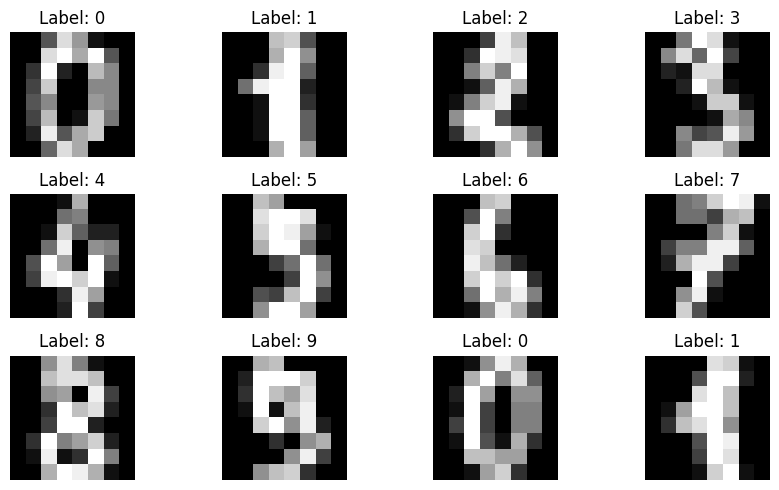

In [5]:
plt.figure(figsize=(9, 5))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Split the dataset

Split the data into training and testing sets. The model learns from the training images and is evaluated on images it has not seen during training. `stratify=y` keeps the class distribution balanced across the two sets.

In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (1437, 8, 8, 1)
Testing images: (360, 8, 8, 1)
Training labels: (1437,)
Testing labels: (360,)


## 7. Build the CNN model

- `Conv2D` learns image patterns such as edges and shapes.
- `MaxPooling2D` reduces the feature-map size.
- `Flatten` converts the learned feature maps into a one-dimensional vector.
- `Dense` layers learn to identify the digit.
- The output layer has 10 neurons, one for each digit (0–9).

In [7]:
cnn_model = models.Sequential([
    layers.Input(shape=(8, 8, 1)),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.Flatten(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,282 (149.54 KB)

 Trainable params: 38,282 (149.54 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Compile the model

- **Adam:** optimizer that updates model weights.
- **Sparse categorical cross-entropy:** loss function for multiple classes when labels are integer values.
- **Accuracy:** measures the proportion of correctly classified digits.

In [8]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 9. Train the model

Train for up to 20 epochs. Early stopping can stop training if validation loss does not improve. The test set is kept separate for final evaluation, so a small part of the training data is used for validation.

In [9]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = cnn_model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.3020 - loss: 2.1181 - val_accuracy: 0.5521 - val_loss: 1.8338
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6258 - loss: 1.3481 - val_accuracy: 0.7847 - val_loss: 0.9018
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7824 - loss: 0.7449 - val_accuracy: 0.8681 - val_loss: 0.5052
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8616 - loss: 0.4824 - val_accuracy: 0.9132 - val_loss: 0.3435
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8825 - loss: 0.3767 - val_accuracy: 0.9306 - val_loss: 0.2581
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9199 - loss: 0.2791 - val_accuracy: 0.9444 - val_loss: 0.2281
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9312 - loss: 0.2494 - val_accuracy: 0.9549 - val_loss: 0.1872
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9452 - loss: 0.1744 - val_accuracy: 0.9583 - val_

## 10. Evaluate the model

Evaluate the final model on the separate test set.

In [10]:
test_loss, test_accuracy = cnn_model.evaluate(x_test, y_test, verbose=0)

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Loss:", round(test_loss, 4))

Test Accuracy: 0.9806
Test Loss: 0.0839


## 11. Plot accuracy and loss

Training and validation curves help us see how model performance changes across epochs. A large gap between the curves can be a sign of overfitting.

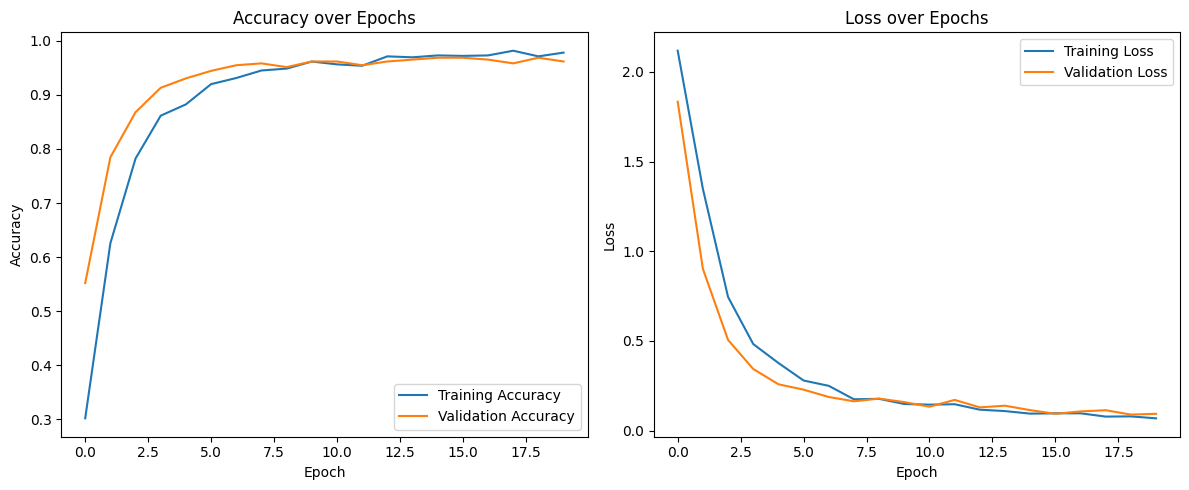

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 12. Confusion matrix and classification report

The confusion matrix shows correct and incorrect predictions for each digit. The classification report provides precision, recall and F1-score for each digit.

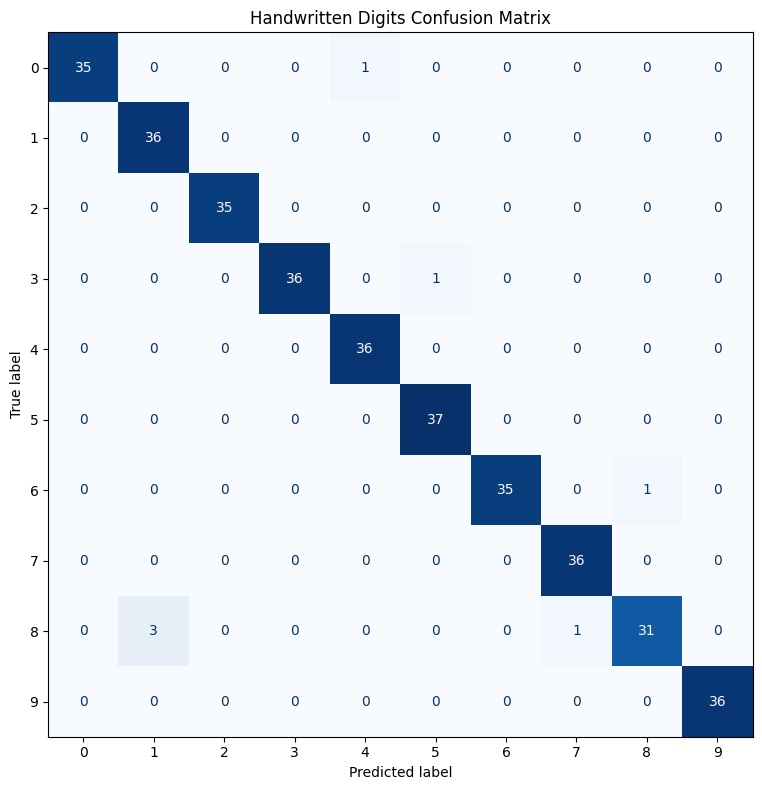

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      1.00      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      0.97      0.99        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.97      0.89      0.93        35
           9       1.00      1.00      1.00        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [12]:
y_probability = cnn_model.predict(x_test, verbose=0)
y_pred = np.argmax(y_probability, axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Handwritten Digits Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, zero_division=0))

## 13. Make sample predictions

Compare the CNN's predicted digit with the actual digit for a few test images.

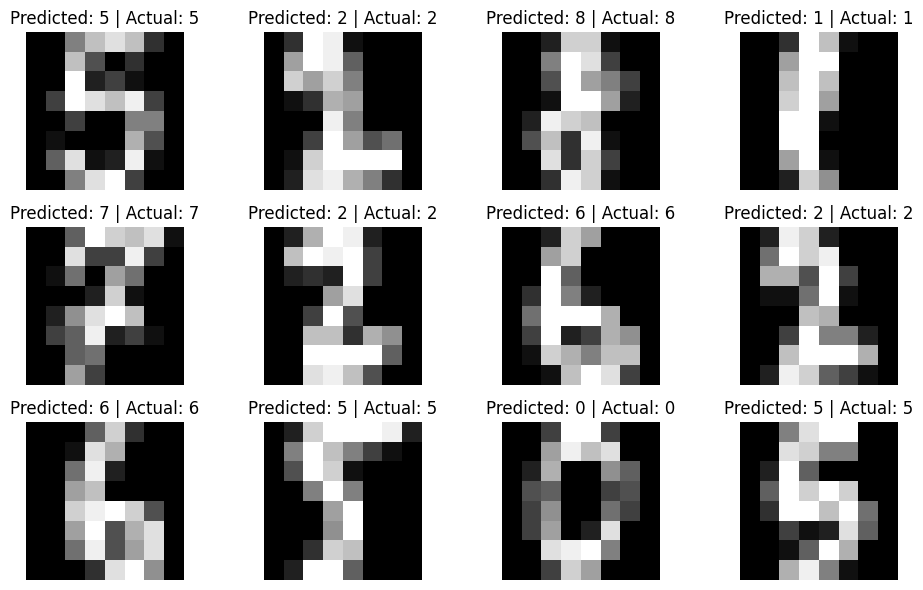

In [13]:
plt.figure(figsize=(10, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"Predicted: {y_pred[i]} | Actual: {y_test[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 14. Save the trained model

Save the trained CNN in Keras format. The file is stored in the current Colab session.

In [14]:
model_path = "handwritten_digits_cnn.keras"
cnn_model.save(model_path)

print("Model saved to:", model_path)

Model saved to: handwritten_digits_cnn.keras


## 15. Download the model

Run this cell in Google Colab to download the model file to your computer.

In [15]:
from google.colab import files
files.download("handwritten_digits_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>